# 05 · Robustness: does the story survive a different split? (5-fold cross-fitting on all 64,000 customers)

Notebook 04 evaluates on one 30% test split (19,200 customers). That is the honest, pre-registered estimate, but a single split has two weaknesses: its confidence intervals are wide, and its numbers depend on which customers happened to land in the test set. Here every one of the **64,000** customers is scored by models that never saw them (5 folds; encoder, T-learner, X-, S-learner, uplift tree and propensity model all re-fitted inside each fold with the settings fixed in notebook 03). The evaluation set is 3.3× larger, so the intervals shrink by roughly 45%.

Also here: the two emails' effects inside the classic purchase-history segments on the full data, because that is the structure the uplift models are implicitly learning.

In [9]:
# Make `src` importable from the notebooks folder (works on Windows and macOS)
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src.config import *
FIG_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_json(obj, name):
    (RESULTS_DIR / name).write_text(json.dumps(obj, indent=2, default=float))

In [10]:
import joblib
from src.preprocessing import load_hillstrom, add_arm
from src.models import TLearner, XLearner, SLearner, UpliftTreeLearner, base_classifier, recommend
from src.crossfit import cross_fit_uplift, cross_fit_single
from src.evaluation import (qini_coefficient, uplift_at_k, share_of_lift_at_k, bootstrap, bootstrap_diff, diff_in_means,
                            policy_incremental_at_k, bootstrap_policy, bootstrap_policy_diff, uplift_curves)

df = add_arm(load_hillstrom()); df.index.name = "customer_id"
M3 = json.loads((RESULTS_DIR / "03_models.json").read_text())
V4 = json.loads((RESULTS_DIR / "04_evaluation.json").read_text())
T_PARAMS = {ARM_CODES[k]: v for k, v in M3["T_params"].items()}
TREE_PARAMS = {ARM_CODES[k]: v for k, v in M3["tree_params"].items()}
COL = {"Random": "#9CA3AF", "Propensity": "#D97706", "T-learner": "#0F766E", "X-learner": "#7C3AED", "S-learner": "#64748B", "Uplift tree": "#DC2626"}
print(len(df), "customers;", df.segment.value_counts().to_dict())
print("T-learner settings:", T_PARAMS); print("Uplift tree settings:", TREE_PARAMS)

64000 customers; {'Womens E-Mail': 21387, 'Mens E-Mail': 21307, 'No E-Mail': 21306}
T-learner settings: {0: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 200}, 1: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}, 2: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 200}}
Uplift tree settings: {1: {'max_depth': 2, 'min_leaf': 1000, 'min_t': 2}, 2: {'max_depth': 2, 'min_leaf': 1000, 'min_t': 2}}


## 1. The structure behind the scores: effects by purchase history (all 64,000 customers)
`mens` and `womens` say whether the customer bought from each line in the past year. Inside each of the three resulting segments, treated minus control (random assignment makes this causal), with 95% CIs.

,customers,share,visit_rate_no_email,uplift_mens,uplift_mens_lo,uplift_mens_hi,uplift_womens,uplift_womens_lo,uplift_womens_hi
segment,,,,,,,,,
men's only,28818.000,0.450,0.100,0.069,0.060,0.079,0.011,0.002,0.020
women's only,28734.000,0.449,0.096,0.071,0.061,0.080,0.074,0.064,0.084
both lines,6448.000,0.101,0.181,0.134,0.109,0.160,0.071,0.046,0.096


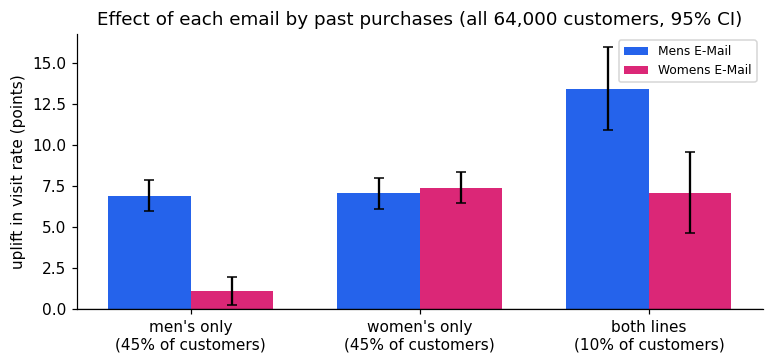

In [11]:
seg_name = np.select([(df.mens == 1) & (df.womens == 0), (df.mens == 0) & (df.womens == 1)], ["men's only", "women's only"], "both lines")
rows = []
for s in ("men's only", "women's only", "both lines"):
    g = df[seg_name == s]
    row = {"segment": s, "customers": len(g), "share": len(g) / len(df), "visit_rate_no_email": g.loc[g.arm == 0, "visit"].mean()}
    for arm in (1, 2):
        d = diff_in_means(g.loc[g.arm == arm, "visit"], g.loc[g.arm == 0, "visit"])
        row[f"uplift_{ARM_SHORT[arm]}"], row[f"uplift_{ARM_SHORT[arm]}_lo"], row[f"uplift_{ARM_SHORT[arm]}_hi"] = d["diff"], d["lo"], d["hi"]
    rows.append(row)
segments = pd.DataFrame(rows)
display(segments.set_index("segment").style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(3); w = 0.36
for i, (arm, col) in enumerate(((1, "#2563EB"), (2, "#DB2777"))):
    u = segments[f"uplift_{ARM_SHORT[arm]}"] * 100
    err = [(segments[f"uplift_{ARM_SHORT[arm]}"] - segments[f"uplift_{ARM_SHORT[arm]}_lo"]) * 100, (segments[f"uplift_{ARM_SHORT[arm]}_hi"] - segments[f"uplift_{ARM_SHORT[arm]}"]) * 100]
    ax.bar(x + (i - 0.5) * w, u, w, color=col, yerr=err, capsize=3, label=ARMS[arm])
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n({sh:.0%} of customers)" for s, sh in zip(segments.segment, segments.share)])
ax.axhline(0, c="black", lw=.8); ax.set_ylabel("uplift in visit rate (points)"); ax.legend(fontsize=8)
ax.set_title("Effect of each email by past purchases (all 64,000 customers, 95% CI)")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_segment_effects.png", bbox_inches="tight"); plt.show()

## 2. Cross-fitted scores for every customer
Same recipe as notebook 03, applied to the full data in 5 stratified folds. The result file `data/processed/all_scores_crossfit.csv` is what the dashboard uses: for every customer, an honest (out-of-fold) uplift estimate from each model and the recommended email.

In [12]:
rng = np.random.default_rng(SEED)
cf = {"T-learner": cross_fit_uplift(df, lambda: TLearner(params=T_PARAMS)),
      "X-learner": cross_fit_uplift(df, lambda: XLearner(stage1=None), fit_kw={"tune": False}),
      "S-learner": cross_fit_uplift(df, lambda: SLearner(params=T_PARAMS[0])),
      "Uplift tree": cross_fit_uplift(df, lambda: UpliftTreeLearner(params=TREE_PARAMS))}
prop_cf = cross_fit_single(df, lambda: base_classifier(**T_PARAMS[0]))
rand = rng.random(len(df))
PREFIX = {"T-learner": "T", "X-learner": "X", "S-learner": "S", "Uplift tree": "UT"}
all_scores = df.copy()
all_scores["propensity"], all_scores["random_score"] = prop_cf, rand
for name, u in cf.items():
    p = PREFIX[name]
    all_scores[f"{p}_uplift_mens"], all_scores[f"{p}_uplift_womens"] = u.uplift_mens.to_numpy(), u.uplift_womens.to_numpy()
    r = recommend(u)
    all_scores[f"{p}_policy_score"], all_scores[f"{p}_best_arm"], all_scores[f"{p}_action"] = r.policy_score.to_numpy(), r.best_arm.to_numpy(), r.recommended_action.to_numpy()
all_scores["default_arm"] = ARM_CODES[M3["default_arm"]]
all_scores.to_csv(PROCESSED_DIR / "all_scores_crossfit.csv", float_format="%.5f")
print("saved", all_scores.shape)
all_scores.filter(regex="uplift").describe().T.round(4)

saved (64000, 36)


,count,mean,std,min,25%,50%,75%,max
T_uplift_mens,"64,000.0000",0.0762,0.0372,-0.1004,0.0544,0.0717,0.0936,0.2860
T_uplift_womens,"64,000.0000",0.0456,0.0449,-0.1993,0.0135,0.0442,0.0784,0.2544
X_uplift_mens,"64,000.0000",0.0757,0.0217,-0.0184,0.0634,0.0723,0.0836,0.2241
X_uplift_womens,"64,000.0000",0.0456,0.0325,-0.0483,0.0179,0.0454,0.0735,0.1412
S_uplift_mens,"64,000.0000",0.0708,0.0242,-0.0047,0.0553,0.0667,0.0798,0.2231
S_uplift_womens,"64,000.0000",0.0426,0.0331,-0.0641,0.0147,0.0452,0.0695,0.1891
UT_uplift_mens,"64,000.0000",0.0773,0.0092,0.0629,0.0735,0.0782,0.0793,0.1201
UT_uplift_womens,"64,000.0000",0.0472,0.0327,-0.0221,0.0140,0.0614,0.0802,0.0830


## 3. Ranking quality per email, with much tighter intervals
Qini coefficient (0 = random) with 95% bootstrap CIs, and paired comparisons on the same resamples. Compare with the test-set values from notebook 04 (last columns).

,email,model,qini,qini_lo,qini_hi,uplift@30%,share_of_lift@50%,qini_test_split
0,Mens E-Mail,Random,-0.0003,-0.0014,0.0007,+0.078,50%,-0.0003
1,Mens E-Mail,Propensity,0.0019,0.0010,0.0029,+0.094,56%,0.0023
2,Mens E-Mail,T-learner,-0.0000,-0.0010,0.0010,+0.073,51%,0.0002
3,Mens E-Mail,X-learner,-0.0002,-0.0013,0.0008,+0.080,48%,-0.0011
4,Mens E-Mail,S-learner,-0.0002,-0.0013,0.0009,+0.082,48%,0.0002
5,Mens E-Mail,Uplift tree,0.0005,-0.0005,0.0014,+0.078,54%,0.0016
6,Womens E-Mail,Random,0.0001,-0.0008,0.0010,+0.047,50%,-0.0010
7,Womens E-Mail,Propensity,0.0008,-0.0001,0.0017,+0.052,57%,0.0024
8,Womens E-Mail,T-learner,0.0029,0.0021,0.0038,+0.070,75%,0.0037
9,Womens E-Mail,X-learner,0.0031,0.0022,0.0040,+0.068,81%,0.0036


,email,comparison,diff,lo,hi,p_a_better,convincing
0,Mens E-Mail,T-learner - Propensity,-0.0019,-0.0030,-0.0006,0.0033,True
1,Mens E-Mail,Uplift tree - Propensity,-0.0014,-0.0027,-0.0002,0.0100,True
2,Mens E-Mail,Uplift tree - T-learner,0.0005,-0.0007,0.0017,0.7633,False
3,Mens E-Mail,S-learner - T-learner,-0.0002,-0.0010,0.0006,0.3067,False
4,Mens E-Mail,X-learner - T-learner,-0.0002,-0.0010,0.0006,0.2933,False
5,Mens E-Mail,Propensity - Random,0.0022,0.0008,0.0038,1.0000,True
6,Womens E-Mail,T-learner - Propensity,0.0021,0.0008,0.0034,1.0000,True
7,Womens E-Mail,Uplift tree - Propensity,0.0031,0.0018,0.0043,1.0000,True
8,Womens E-Mail,Uplift tree - T-learner,0.0009,0.0001,0.0017,0.9800,True
9,Womens E-Mail,S-learner - T-learner,0.0004,-0.0001,0.0009,0.9100,False


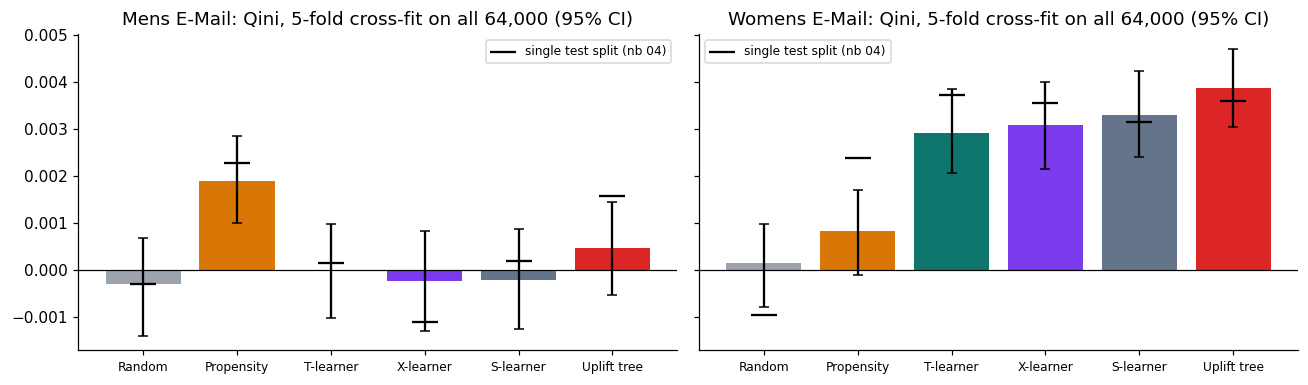

In [13]:
y_all, arm_all = df.visit.to_numpy(), df.arm.to_numpy()
SCORES = {**{k: v for k, v in cf.items()}, "Propensity": prop_cf, "Random": rand}
def score_for(name, arm):
    s = SCORES[name]
    return s[f"uplift_{ARM_SHORT[arm]}"].to_numpy() if isinstance(s, pd.DataFrame) else np.asarray(s)
test_rank = {(r["email"], r["model"]): r for r in V4["ranking"]}
rows = []
for arm in (1, 2):
    m = np.isin(arm_all, [0, arm]); y, t = y_all[m], (arm_all[m] == arm).astype(int)
    for name in ("Random", "Propensity", "T-learner", "X-learner", "S-learner", "Uplift tree"):
        s = score_for(name, arm)[m]
        b = bootstrap(qini_coefficient, y, t, s, n_boot=N_BOOT)
        rows.append({"email": ARMS[arm], "model": name, "qini": b["estimate"], "qini_lo": b["lo"], "qini_hi": b["hi"],
                     "uplift@30%": uplift_at_k(y, t, s, .3), "share_of_lift@50%": 0.5 if name == "Random" else share_of_lift_at_k(y, t, s, .5),
                     "qini_test_split": test_rank[(ARMS[arm], name)]["qini"]})
cf_rank = pd.DataFrame(rows)
display(cf_rank.style.format({c: "{:.4f}" for c in ("qini", "qini_lo", "qini_hi", "qini_test_split")} | {"uplift@30%": "{:+.3f}", "share_of_lift@50%": "{:.0%}"}))

pairs = [("T-learner", "Propensity"), ("Uplift tree", "Propensity"), ("Uplift tree", "T-learner"), ("S-learner", "T-learner"), ("X-learner", "T-learner"), ("Propensity", "Random")]
prow = []
for arm in (1, 2):
    m = np.isin(arm_all, [0, arm]); y, t = y_all[m], (arm_all[m] == arm).astype(int)
    for a, b in pairs:
        d = bootstrap_diff(qini_coefficient, y, t, score_for(a, arm)[m], score_for(b, arm)[m], n_boot=N_BOOT)
        prow.append({"email": ARMS[arm], "comparison": f"{a} - {b}", **d})
cf_paired = pd.DataFrame(prow); cf_paired["convincing"] = (cf_paired.lo > 0) | (cf_paired.hi < 0)
display(cf_paired)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, arm in zip(axes, (1, 2)):
    d = cf_rank[cf_rank.email == ARMS[arm]]
    ax.bar(d.model, d.qini, color=[COL[mname] for mname in d.model], yerr=[d.qini - d.qini_lo, d.qini_hi - d.qini], capsize=3)
    ax.scatter(d.model, d.qini_test_split, color="black", marker="_", s=300, label="single test split (nb 04)", zorder=3)
    ax.axhline(0, c="black", lw=.8); ax.set_title(f"{ARMS[arm]}: Qini, 5-fold cross-fit on all 64,000 (95% CI)"); ax.tick_params(axis="x", labelsize=8); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_crossfit_qini.png", bbox_inches="tight"); plt.show()

## 4. The whole campaign (who + which email) on all 64,000 customers
Extra visits per 100 targeted customers when each strategy contacts its top K% (Random = expected value, i.e. the everyone estimate), with paired bootstrap tests of the key comparisons.

In [19]:
N_BOOT_POLICY = 300
ones = np.ones(len(df), dtype=int)
STRATS = {"Random": (rand, ones), "Propensity": (prop_cf, ones),
          "T-learner": (all_scores.T_policy_score.to_numpy(), all_scores.T_best_arm.to_numpy()),
          "Uplift tree": (all_scores.UT_policy_score.to_numpy(), all_scores.UT_best_arm.to_numpy())}
KS = [0.1, 0.2, 0.3, 0.5, 1.0]
pol_rows = []
for name, (s, pa) in STRATS.items():
    for k in KS:
        b = bootstrap_policy(y_all, arm_all, pa, s, 1.0 if name == "Random" else k, n_boot=N_BOOT_POLICY)
        pol_rows.append({"strategy": name, "k": k, "visit": b["estimate"], "visit_lo": b["lo"], "visit_hi": b["hi"]})
cf_policy = pd.DataFrame(pol_rows)
display((cf_policy.pivot(index="k", columns="strategy", values="visit") * 100).round(2))

cmp_rows = []
for k in (0.3, 0.5):
    for a, b in [("Uplift tree", "Random"), ("T-learner", "Random"), ("Uplift tree", "Propensity"), ("T-learner", "Propensity")]:
        (sa, pa), (sb, pb) = STRATS[a], STRATS[b]
        d = bootstrap_policy_diff(y_all, arm_all, pa, sa, pb, sb, k, k_b=(1.0 if b == "Random" else k), n_boot=N_BOOT_POLICY)
        cmp_rows.append({"k": k, "comparison": f"{a} - {b}", **d})
cf_policy_cmp = pd.DataFrame(cmp_rows); cf_policy_cmp["convincing"] = (cf_policy_cmp.lo > 0) | (cf_policy_cmp.hi < 0)
display(cf_policy_cmp)

strategy,Propensity,Random,T-learner,Uplift tree
k,,,,
0.1000,11.8400,7.6600,8.6400,9.4300
0.2000,9.5700,7.6600,7.9800,7.9800
0.3000,9.3300,7.6600,7.3800,7.5800
0.5000,8.4900,7.6600,7.7900,7.4400
1.0000,7.6600,7.6600,7.5100,7.4600


,k,comparison,diff,lo,hi,p_a_better,convincing
0,0.3000,Uplift tree - Random,-0.0008,-0.0134,0.0110,0.4667,False
1,0.3000,T-learner - Random,-0.0028,-0.0133,0.0090,0.3133,False
2,0.3000,Uplift tree - Propensity,-0.0175,-0.0319,-0.0017,0.0200,True
3,0.3000,T-learner - Propensity,-0.0195,-0.0338,-0.0047,0.0033,True
4,0.5000,Uplift tree - Random,-0.0021,-0.0085,0.0079,0.4267,False
5,0.5000,T-learner - Random,0.0013,-0.0056,0.0084,0.6667,False
6,0.5000,Uplift tree - Propensity,-0.0104,-0.0185,0.0018,0.0467,False
7,0.5000,T-learner - Propensity,-0.0070,-0.0160,0.0027,0.0667,False


## 5. The women's category campaign on all 64,000 customers
Share of the women's email's total effect kept when only the top 30% / 50% are contacted, by model.

In [20]:
m = np.isin(arm_all, [0, 2]); y, t = y_all[m], (arm_all[m] == 2).astype(int)
wrows = []
for name in ("Random", "Propensity", "T-learner", "S-learner", "Uplift tree"):
    s = score_for(name, 2)[m]
    for k in (0.3, 0.5):
        wrows.append({"model": name, "k": k, "share_of_lift": k if name == "Random" else share_of_lift_at_k(y, t, s, k),
                      "uplift_in_group": (y[t == 1].mean() - y[t == 0].mean()) if name == "Random" else uplift_at_k(y, t, s, k)})
cf_womens = pd.DataFrame(wrows)
display(cf_womens.pivot(index="model", columns="k", values="share_of_lift").style.format("{:.0%}"))

k,0.300000,0.500000
model,,
Propensity,35%,57%
Random,30%,50%
S-learner,47%,81%
T-learner,47%,75%
Uplift tree,49%,81%


In [21]:
save_json({"segments": segments.to_dict("records"), "ranking": cf_rank.to_dict("records"), "paired": cf_paired.to_dict("records"),
           "policy": cf_policy.to_dict("records"), "policy_cmp": cf_policy_cmp.to_dict("records"),
           "womens_lift": cf_womens.to_dict("records"), "n_customers": int(len(df))}, "05_robustness.json")
print("saved")

saved


# What We Found

### 1. Customer segments explain differences in email response

Across all 64,000 customers, the women's email has a relatively small estimated effect on men's-only buyers (+1.1 percentage points), but a substantially stronger effect on women's-only buyers (+7.4 points) and customers who previously purchased both categories (+7.1 points).

The men's email shows positive estimated uplift across all three segments (+6.9, +7.1, and +13.4 points, respectively).

These results suggest that past purchasing behavior helps identify differences in responsiveness to promotional emails.

### 2. Uplift modeling improves ranking for the women's email

Using five-fold cross-fitting across all 64,000 customers, the Qini coefficients are:

- Uplift Tree: **0.0039** (95% CI: 0.0031–0.0047)
- S-Learner: **0.0033**
- X-Learner: **0.0031**
- T-Learner: **0.0029**
- Propensity: **0.0008**
- Random: approximately zero

All four uplift models outperform propensity in the reported paired bootstrap comparisons.

The uplift tree achieves the highest Qini coefficient, although its advantage over the T-Learner should be interpreted cautiously.

**Business interpretation:** Targeting the top 50% of customers with the uplift tree captures approximately 81% of the women's email's incremental visits, compared with 75% for the T-Learner, 57% for propensity, and 50% for random targeting.

### 3. Cross-fitting provides an additional robustness check

Compared with the single held-out test split, the T-Learner achieves a lower Qini coefficient under five-fold cross-fitting, while the uplift tree performs similarly.

This suggests that some results are sensitive to the particular train/test division.

Cross-fitting provides a broader evaluation but does not eliminate all possible sources of bias or uncertainty.

### 4. Propensity remains stronger for the men's email

For the men's email, propensity achieves a Qini coefficient of **0.0019** (95% CI: 0.0010–0.0029), outperforming random ranking and the T-Learner in the reported comparisons.

The uplift models do not demonstrate a consistent advantage over propensity.

The men's email has a broadly positive average effect, with the strongest observed response among customers who previously purchased both product categories.

### 5. Whole-campaign personalization does not demonstrate a consistent advantage

Improving the ranking for an individual email does not necessarily improve a campaign that must decide both **whom to contact and which email to send**.

At 30% targeting, the estimated incremental visits per 100 contacted customers are:

| Strategy | Extra visits per 100 |
|---|---:|
| Propensity | **9.33** |
| Random | 7.66 |
| T-Learner | 7.38 |
| Uplift Tree | 7.58 |

In the paired bootstrap comparisons using 300 resamples, neither uplift model significantly outperforms random targeting at 30% targeting. Both the T-Learner and uplift tree perform significantly worse than propensity, with their 95% confidence intervals for the differences excluding zero.

These results should be confirmed using the final bootstrap settings before making definitive statistical claims.

### 6. Business implications

Uplift modeling is particularly useful for the women's email, where customer responses differ substantially across purchasing segments.

For the complete two-email campaign, propensity remains a competitive and simpler targeting strategy.

The uplift tree is a promising candidate for a women's-email-specific campaign, but its financial impact should be validated through a future randomized campaign.

### Bottom Line

**Uplift modeling improves our ability to identify customers who are more responsive to the women's email, but better uplift ranking does not automatically produce better whole-campaign performance or higher profit.**

The best approach depends on the specific email, the campaign objective, contact costs, and evidence from randomized evaluation.